# Data Massaging 2
- Uso avanzado de pandas
- Primeros análisis
- Combinación de dataframes
- Funciones lambda aplicadas a dataframes
- Manejo de datos avanzado

# Agregación de Datos

In [68]:
# Importar un archivo CSV con Pandas

# Se importa la librería pandas
# La documentación de la librería se puede ver en: https://pandas.pydata.org/docs/
import pandas as pd

# Otras librerías necesarias
import numpy as np
import os

# Se usa la función read_csv para leer el archivo .csv
# Este archivo es el de las películas de Netlix que hemos venido utilizando
# y lo ingesta en la variable df
df = pd.read_csv(r'netflix_titles_2.csv')

In [69]:
df.head(5)

,Unnamed: 0,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_num,duration_unit
0,0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,min
1,1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,season
2,2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,season
3,3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,season
4,4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,season


In [70]:
# Funciones estadísticas básicas 
# Utilizando los campos númericos
# Para listar los campos se tiene la función describe
df.describe()

,Unnamed: 0,release_year,duration_num
count,8807.000000,8807.000000,8807.000000
mean,4403.000000,2014.180198,69.848530
std,2542.506244,8.819312,50.806431
min,0.000000,1925.000000,1.000000
25%,2201.500000,2013.000000,2.000000
50%,4403.000000,2017.000000,88.000000
75%,6604.500000,2019.000000,106.000000
max,8806.000000,2021.000000,312.000000


In [71]:
# Se elimina la coluna con .drop
# df.drop('Unnamed: 0', axis = 'columns', inplace = True)

In [72]:
# También se pueden obtener las estadísticas aisladas
print('Media =',  df['duration_num'].mean())
print('Min =', df['duration_num'].min())
print('Max =', df['duration_num'].max())

Media = 69.84852957874418
Min = 1.0
Max = 312.0


In [73]:
# Agregación de datos, si es película (min) o serie (season)
# Cuenta cuántos son
df.groupby('duration_unit').size()

duration_unit
min       6131
season    2676
dtype: int64

<Axes: xlabel='duration_unit'>

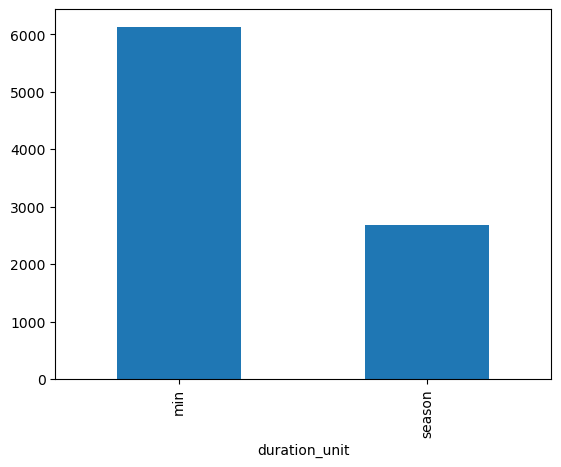

In [74]:
# Un gráfico simple de barras del número de películas y series
df.groupby('duration_unit').size().plot.bar()

# ¿Cómo calcular el total en horas tanto de películas como series?
- Las películas vienen en minutos, por lo que el número total simplemente se debería dividir para 60 min

In [75]:
# También se puede hacer la suma
movies_minutes = df.loc[df['duration_unit'] == 'min', 'duration_num'].sum()

# Muestra las estadísticas, con 2 decimales
print(f'Total Minutes for Movies = {movies_minutes:2f}')
print(f'Total Hours for Movies = {movies_minutes/60:.2f}')

Total Minutes for Movies = 610433.000000
Total Hours for Movies = 10173.88


- Las series se tienen que calcular
- Ahora se calcula la cantidad de seasons
- Se asume que cada season tiene un promedio de 7 episodios
- Y cada episodio dura 30 minutos
- Así, si es que una serie tiene 1 season = 7*30 = 210 min

In [76]:
# Largo en minutos
len_season_min = 7*30

# largo en horas de una season
len_season_hr = len_season_min/60

print(len_season_hr)

3.5


In [77]:
# Calcula el total de Seasons del dataset
total_seasons_dataset = df.loc[df['duration_unit'] == 'season', 'duration_num'].sum()
print('Total de Horas en Seasons = ', total_seasons_dataset)

# Ahora se multiplica el total de Seasons por el largo de cada Season
total_season_hr_dataset = total_seasons_dataset * len_season_hr

print('Total de horas en Series = ', total_season_hr_dataset)

Total de Horas en Seasons =  4723.0
Total de horas en Series =  16530.5


In [78]:
df.head()

,Unnamed: 0,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_num,duration_unit
0,0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,min
1,1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,season
2,2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,season
3,3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,season
4,4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,season


In [79]:
# Otra pregunta, las películas son más largas según su rating?
df[['title', 'country', 'release_year', 'duration_num', 'rating']].loc[(df['duration_unit'] == 'min')]

,title,country,release_year,duration_num,rating
0,Dick Johnson Is Dead,United States,2020,90.0,PG-13
6,My Little Pony: A New Generation,NaN,2021,91.0,PG
7,Sankofa,"United States, Ghana, Burkina Faso, United Kin...",1993,125.0,TV-MA
9,The Starling,United States,2021,104.0,PG-13
12,Je Suis Karl,"Germany, Czech Republic",2021,127.0,TV-MA
...,...,...,...,...,...
8801,Zinzana,"United Arab Emirates, Jordan",2015,96.0,TV-MA
8802,Zodiac,United States,2007,158.0,R
8804,Zombieland,United States,2009,88.0,R
8805,Zoom,United States,2006,88.0,PG


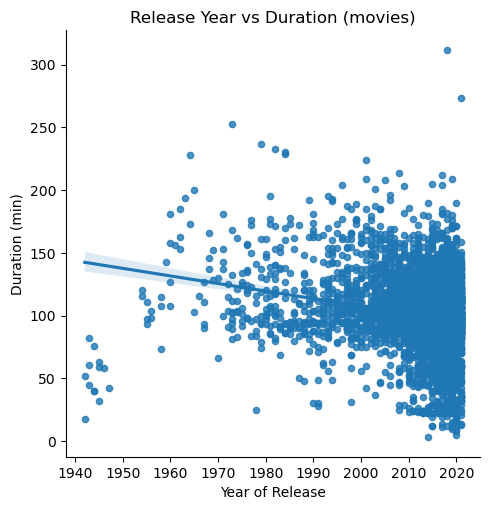

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

df_movies = df[['title', 'country', 'release_year', 'duration_num', 'rating']].loc[df['duration_unit'] == 'min']
sns.lmplot( x = 'release_year', y= 'duration_num', data = df_movies, fit_reg = True, scatter_kws = {'marker': 'D', 's':20})

plt.title('Release Year vs Duration (movies)')
plt.xlabel('Year of Release')
plt.ylabel('Duration (min)')
plt.show()


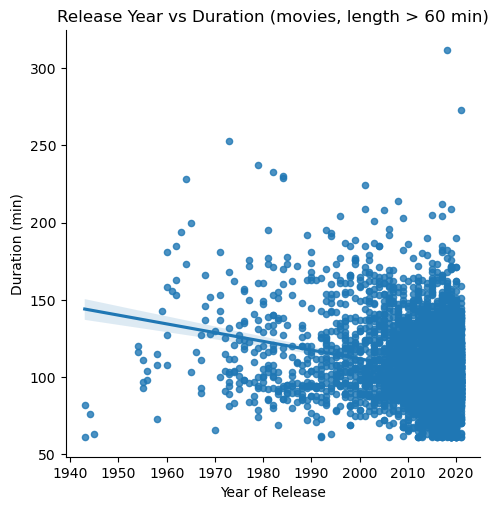

In [81]:
# Que pasaría si es que se toman en cuenta nada más películas de por lo menos 60 minutos?

df_movies2 = df[['title', 'country', 'release_year', 'duration_num', 'rating']].loc[(df['duration_unit'] == 'min') & (df['duration_num'] > 60)]
sns.lmplot(x = 'release_year', y = 'duration_num', data = df_movies2, fit_reg = True, scatter_kws = {'marker': 's', 's': 20})

plt.title('Release Year vs Duration (movies, length > 60 min)')
plt.xlabel('Year of Release')
plt.ylabel('Duration (min)')
plt.show()

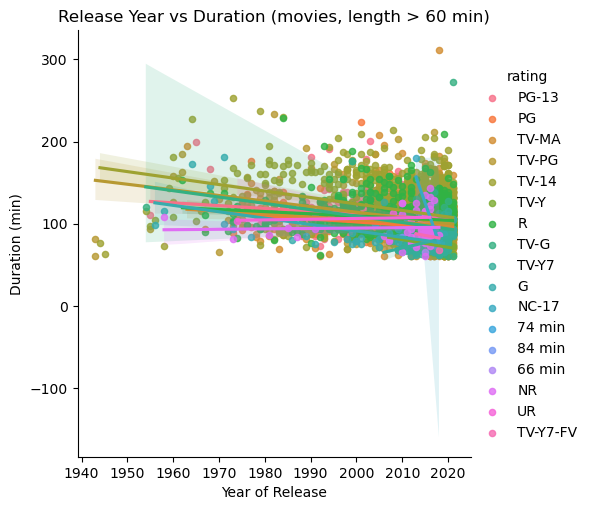

In [82]:
# Contestando la pregunta anterior
sns.lmplot(x = 'release_year', y = 'duration_num', data = df_movies2, hue = 'rating', fit_reg= True, scatter_kws= {'marker': 's', 's': 20})
plt.title('Release Year vs Duration (movies, length > 60 min)')
plt.xlabel('Year of Release')
plt.ylabel('Duration (min)')
plt.show()

In [83]:
# Agrupaciones simples
df.groupby('type').count()['show_id']

type
Movie      6131
TV Show    2676
Name: show_id, dtype: int64

In [84]:
# Películas por país
df.groupby('country').count()['show_id'].sort_values(ascending = False)[0:10]

country
United States     2818
India              972
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Egypt              106
Name: show_id, dtype: int64

<Axes: xlabel='country'>

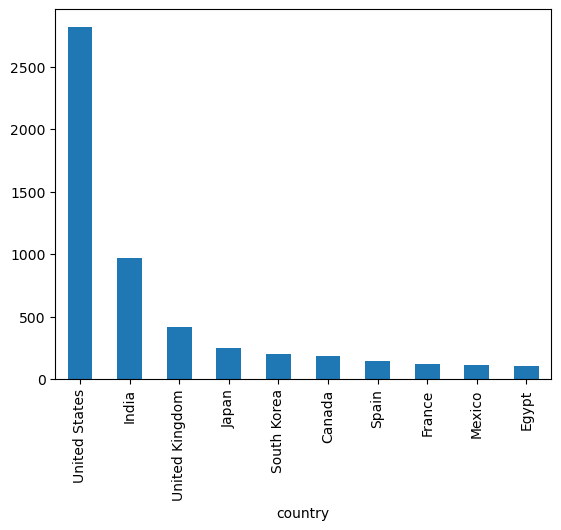

In [85]:
# Películas por país (Gráfico de barras)
df.groupby('country').count()['show_id'].sort_values(ascending = False)[0:10].plot.bar()

<Axes: ylabel='show_id'>

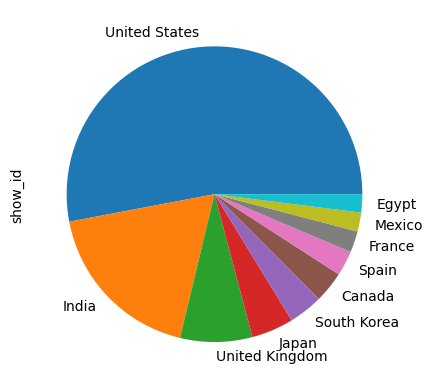

In [86]:
# Películas por país (Gráfico de pastel)
df.groupby('country').count()['show_id'].sort_values(ascending = False)[0:10].plot.pie()

In [87]:
# Películas por rating
df.groupby('rating').count()['show_id'].sort_values(ascending = False)[0:10]

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: show_id, dtype: int64

<Axes: ylabel='show_id'>

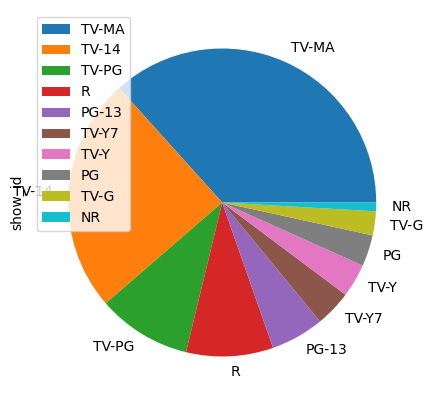

In [88]:
df.groupby('rating').count()['show_id'].sort_values(ascending = False)[0:10].plot.pie(y = 'rating', figsize = (5,5), legend = True)
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html

# Combinación y Manejo de DataFrames

In [89]:
# Nuevo DataFrame
clase = [('Jorge', 22, 'MX'), 
         ('Anita', 31, 'MX'),
         ('Raul', 16, 'BR'),
         ('Simon', 41, 'BR'),
         ('Diego', 33, 'PA'),
         ('Jorge', 35, 'PA'),
         ('Almendra', 35, 'CO'),
         ('Mary', 37, 'CO'),
         ('Peter', 40, 'EC'),
         ('Andrés', 48, 'EC')
         ]
df_clase = pd.DataFrame(clase, columns = ['Nombre', 'Edad', 'País'],)

In [90]:
# DataFrame 2, con otra clase
clase_2 = [('Mauricio', 25, 'MX'),
           ('Gladys', 41, 'PA'),
           ('Sebastián', 36, 'BR')
           ]
df_clase_2 = pd.DataFrame(clase_2, columns = ['Nombre', 'Edad', 'País'])

In [91]:
df_clase

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [92]:
df_clase_2

,Nombre,Edad,País
0,Mauricio,25,MX
1,Gladys,41,PA
2,Sebastián,36,BR


In [93]:
# Con el uso del comando append, se pueden combinar 2 dataframes
df_clase_1y2 = pd.concat([df_clase, df_clase_2])

In [94]:
df_clase_1y2

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [95]:
# Reindexación
df_clase_1y2.reset_index(level = None, drop = True, inplace = True)

In [96]:
df_clase_1y2

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


# Eliminación de datos

In [97]:
df_clase_elim = df_clase_1y2

In [98]:
df_clase_elim

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [99]:
# Eliminar 2 registros, utilizando drop
df_clase_elim = df_clase_elim.drop(2)

In [100]:
df_clase_elim

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC
10,Mauricio,25,MX


In [101]:
# Elimina dos al mismo tiempo
df_clase_elim.drop([7,8], axis = 0, inplace = True)

In [102]:
df_clase_elim

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
9,Andrés,48,EC
10,Mauricio,25,MX
11,Gladys,41,PA
12,Sebastián,36,BR


In [103]:
# Registros que cumplen con la condición de abajo
df_clase_elim[df_clase_elim['Edad'] < 40]

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
10,Mauricio,25,MX
12,Sebastián,36,BR


In [104]:
# Drop con condición
# Se eliminan a todos los alumnos menores de 40 años
df_clase_elim.drop(df_clase_elim[df_clase_elim['Edad'] < 40].index, inplace= True)

In [105]:
df_clase_elim

,Nombre,Edad,País
3,Simon,41,BR
9,Andrés,48,EC
11,Gladys,41,PA


# Actualización de datos

In [106]:
df_clase_Upd = df_clase_1y2

In [107]:
df_clase_Upd

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [108]:
# Actualizar datos de un DataFrame
# Usando loc

df_clase_Upd.loc[3, 'Nombre'] = 'Ramón'

In [109]:
df_clase_Upd

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Ramón,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [110]:
# Filtro para el argumento de abajo
df_clase_Upd[df_clase_Upd['Edad'] == 41]

,Nombre,Edad,País
3,Ramón,41,BR
11,Gladys,41,PA


In [111]:
# Actualizar basado en una condición
# Rebaja un año la edad
df_clase_Upd.loc[(df_clase_Upd[df_clase_Upd['Edad'] == 41].index), 'Edad'] = 40


In [112]:
df_clase_Upd

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Ramón,40,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


# Merge de DataFrames

In [113]:
clase = [('Jorge', 22, 'MX'), 
         ('Anita', 31, 'MX'),
         ('Raul', 16, 'BR'),
         ('Simon', 41, 'BR'),
         ('Diego', 33, 'PA'),
         ('Jorge', 35, 'PA'),
         ('Almendra', 35, 'CO'),
         ('Mary', 37, 'CO'),
         ('Peter', 40, 'EC'),
         ('Andrés', 48, 'EC')
         ]

df_clase_3 = pd.DataFrame(clase, columns = ['Nombre', 'Edad', 'País'],)

In [114]:
clase = [('Jorge', 22, 'MX'), 
         ('Anita', 31, 'MX'),
         ('Raul', 16, 'BR'),
         ('Simon', 41, 'BR')
         ]

df_clase_4 = pd.DataFrame(clase, columns=['Nombre', 'Edad', 'País'],)


In [115]:
df_clase_3

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [116]:
df_clase_4

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR


In [117]:
df_clase_3.merge(df_clase_4, left_on= 'Nombre', right_on= 'Nombre')

,Nombre,Edad_x,País_x,Edad_y,País_y
0,Jorge,22,MX,22,MX
1,Anita,31,MX,31,MX
2,Raul,16,BR,16,BR
3,Simon,41,BR,41,BR
4,Jorge,35,PA,22,MX


In [118]:
df_clase_3.merge(df_clase_4, how = 'inner', on= 'Nombre')

,Nombre,Edad_x,País_x,Edad_y,País_y
0,Jorge,22,MX,22,MX
1,Anita,31,MX,31,MX
2,Raul,16,BR,16,BR
3,Simon,41,BR,41,BR
4,Jorge,35,PA,22,MX


In [119]:
# Producto cartesiano
df_clase_3.merge(df_clase_4, how = 'cross')

,Nombre_x,Edad_x,País_x,Nombre_y,Edad_y,País_y
0,Jorge,22,MX,Jorge,22,MX
1,Jorge,22,MX,Anita,31,MX
2,Jorge,22,MX,Raul,16,BR
3,Jorge,22,MX,Simon,41,BR
4,Anita,31,MX,Jorge,22,MX
5,Anita,31,MX,Anita,31,MX
6,Anita,31,MX,Raul,16,BR
7,Anita,31,MX,Simon,41,BR
8,Raul,16,BR,Jorge,22,MX
9,Raul,16,BR,Anita,31,MX


# Aplicando funciones lambda a un DataFrame
- Las funciones lambda son funciones anónimas (no tienen declaración formal)
- Pueden tomar cualquier número de argumentos, pero solamente tener una expresión
- Son anónimas, no necesitan de declaración, o statements internos como "return", "pass", etc
- Muy productivas y eficientes
- Las van a utilizar durante toda su vida de programación con Python
- Comando apply

In [120]:
# Nuevo DataFrame
clase = [('Jorge', 22, 'MX'), 
         ('Anita', 31, 'MX'),
         ('Raul', 16, 'BR'),
         ('Simon', 41, 'BR'),
         ('Diego', 33, 'PA'),
         ('Jorge', 35, 'PA'),
         ('Almendra', 35, 'CO'),
         ('Mary', 37, 'CO'),
         ('Peter', 40, 'EC'),
         ('Andrés', 48, 'EC')
         ]

df_clase = pd.DataFrame(clase, columns = ['Nombre', 'Edad', 'País'],)

In [121]:
df_clase

,Nombre,Edad,País
0,Jorge,22,MX
1,Anita,31,MX
2,Raul,16,BR
3,Simon,41,BR
4,Diego,33,PA
5,Jorge,35,PA
6,Almendra,35,CO
7,Mary,37,CO
8,Peter,40,EC
9,Andrés,48,EC


In [122]:
# Buscando si la edad es par o impar
df_clase['Par-Impar'] = df_clase['Edad'].apply(lambda x:'Impar' if int(x) % 2 else 'Par')
# En este caso, Edad se envía como parámetro a la función lambda, que busca si Edad / 2 es entero o no

In [123]:
df_clase

,Nombre,Edad,País,Par-Impar
0,Jorge,22,MX,Par
1,Anita,31,MX,Impar
2,Raul,16,BR,Par
3,Simon,41,BR,Impar
4,Diego,33,PA,Impar
5,Jorge,35,PA,Impar
6,Almendra,35,CO,Impar
7,Mary,37,CO,Impar
8,Peter,40,EC,Par
9,Andrés,48,EC,Par


In [124]:
df_clase.groupby('Par-Impar').count()['Nombre']

Par-Impar
Impar    6
Par      4
Name: Nombre, dtype: int64

<Axes: xlabel='Par-Impar'>

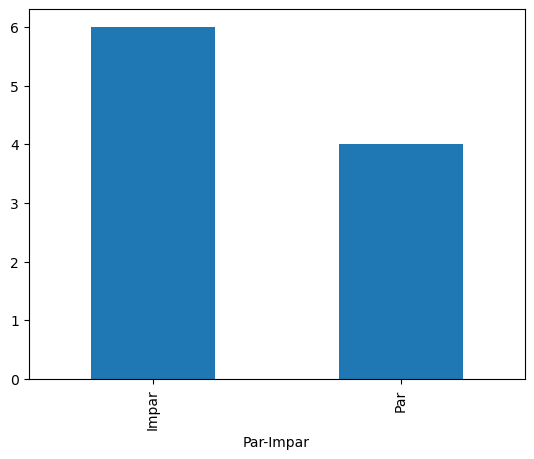

In [125]:
df_clase.groupby('Par-Impar').count()['Nombre'].plot.bar()

In [126]:
# Ejemplo lambda 2: Descuento del 10% para mayores de 37 años
df_clase['Dcto'] = df_clase['Edad'].apply(lambda x:0.1 if x > 40 else 0.0 )

In [127]:
df_clase

,Nombre,Edad,País,Par-Impar,Dcto
0,Jorge,22,MX,Par,0.0
1,Anita,31,MX,Impar,0.0
2,Raul,16,BR,Par,0.0
3,Simon,41,BR,Impar,0.1
4,Diego,33,PA,Impar,0.0
5,Jorge,35,PA,Impar,0.0
6,Almendra,35,CO,Impar,0.0
7,Mary,37,CO,Impar,0.0
8,Peter,40,EC,Par,0.0
9,Andrés,48,EC,Par,0.1


In [128]:
# Ejemplo lambda 3: Zona horaria
# Referencia: https://pynative.com/list-all-timezones-in-python/#:~:text:))
import pytz

df_clase['ZonaHoraria'] = df_clase['País'].apply(lambda x:pytz.country_timezones(x))

In [129]:
df_clase

,Nombre,Edad,País,Par-Impar,Dcto,ZonaHoraria
0,Jorge,22,MX,Par,0.0,"[America/Mexico_City, America/Cancun, America/..."
1,Anita,31,MX,Impar,0.0,"[America/Mexico_City, America/Cancun, America/..."
2,Raul,16,BR,Par,0.0,"[America/Noronha, America/Belem, America/Forta..."
3,Simon,41,BR,Impar,0.1,"[America/Noronha, America/Belem, America/Forta..."
4,Diego,33,PA,Impar,0.0,[America/Panama]
5,Jorge,35,PA,Impar,0.0,[America/Panama]
6,Almendra,35,CO,Impar,0.0,[America/Bogota]
7,Mary,37,CO,Impar,0.0,[America/Bogota]
8,Peter,40,EC,Par,0.0,"[America/Guayaquil, Pacific/Galapagos]"
9,Andrés,48,EC,Par,0.1,"[America/Guayaquil, Pacific/Galapagos]"


In [ ]:

# Se obtendrá country como el país desde pytz

df_clase['NombrePaís'] = df_clase['País'].apply(lambda x:pytz.country_names[x])


In [131]:
df_clase

,Nombre,Edad,País,Par-Impar,Dcto,ZonaHoraria,NombrePaís
0,Jorge,22,MX,Par,0.0,"[America/Mexico_City, America/Cancun, America/...",Mexico
1,Anita,31,MX,Impar,0.0,"[America/Mexico_City, America/Cancun, America/...",Mexico
2,Raul,16,BR,Par,0.0,"[America/Noronha, America/Belem, America/Forta...",Brazil
3,Simon,41,BR,Impar,0.1,"[America/Noronha, America/Belem, America/Forta...",Brazil
4,Diego,33,PA,Impar,0.0,[America/Panama],Panama
5,Jorge,35,PA,Impar,0.0,[America/Panama],Panama
6,Almendra,35,CO,Impar,0.0,[America/Bogota],Colombia
7,Mary,37,CO,Impar,0.0,[America/Bogota],Colombia
8,Peter,40,EC,Par,0.0,"[America/Guayaquil, Pacific/Galapagos]",Ecuador
9,Andrés,48,EC,Par,0.1,"[America/Guayaquil, Pacific/Galapagos]",Ecuador


In [132]:
# Finalmente, se obtiene la capital de cada país, en el caso de que se 
# tengan que generar comunicados o envíos físicos
# Primero, se instala la librería - pip install countryinfo

# Se va a utilizar la función CountryInfo(country).capital()
# Donde country es el país

from countryinfo import CountryInfo
df_clase['Capital'] = df_clase['NombrePaís'].apply(lambda x:CountryInfo(x).capital())

In [133]:
df_clase

,Nombre,Edad,País,Par-Impar,Dcto,ZonaHoraria,NombrePaís,Capital
0,Jorge,22,MX,Par,0.0,"[America/Mexico_City, America/Cancun, America/...",Mexico,Mexico City
1,Anita,31,MX,Impar,0.0,"[America/Mexico_City, America/Cancun, America/...",Mexico,Mexico City
2,Raul,16,BR,Par,0.0,"[America/Noronha, America/Belem, America/Forta...",Brazil,Brasília
3,Simon,41,BR,Impar,0.1,"[America/Noronha, America/Belem, America/Forta...",Brazil,Brasília
4,Diego,33,PA,Impar,0.0,[America/Panama],Panama,Panama City
5,Jorge,35,PA,Impar,0.0,[America/Panama],Panama,Panama City
6,Almendra,35,CO,Impar,0.0,[America/Bogota],Colombia,Bogotá
7,Mary,37,CO,Impar,0.0,[America/Bogota],Colombia,Bogotá
8,Peter,40,EC,Par,0.0,"[America/Guayaquil, Pacific/Galapagos]",Ecuador,Quito
9,Andrés,48,EC,Par,0.1,"[America/Guayaquil, Pacific/Galapagos]",Ecuador,Quito


In [136]:
# Se abre un curso en Portugués, por lo que los alumnos de Brasil tienen que salir del listado actual
index_br = df_clase[df_clase['País'] == 'BR'].index

In [137]:
# Corresponde a los registros 2 y 3
index_br

Index([2, 3], dtype='int64')

In [138]:
# Elimina los registros correspondientes
df_clase.drop(index_br, inplace=True)

In [139]:
df_clase

,Nombre,Edad,País,Par-Impar,Dcto,ZonaHoraria,NombrePaís,Capital
0,Jorge,22,MX,Par,0.0,"[America/Mexico_City, America/Cancun, America/...",Mexico,Mexico City
1,Anita,31,MX,Impar,0.0,"[America/Mexico_City, America/Cancun, America/...",Mexico,Mexico City
4,Diego,33,PA,Impar,0.0,[America/Panama],Panama,Panama City
5,Jorge,35,PA,Impar,0.0,[America/Panama],Panama,Panama City
6,Almendra,35,CO,Impar,0.0,[America/Bogota],Colombia,Bogotá
7,Mary,37,CO,Impar,0.0,[America/Bogota],Colombia,Bogotá
8,Peter,40,EC,Par,0.0,"[America/Guayaquil, Pacific/Galapagos]",Ecuador,Quito
9,Andrés,48,EC,Par,0.1,"[America/Guayaquil, Pacific/Galapagos]",Ecuador,Quito


In [144]:
# Agrupamiento por país
#print(df_clase.groupby('País').size())

# Agrupamiento por edad
print(df_clase.groupby('País')['Edad'].mean()) 

País
CO    36.0
EC    44.0
MX    26.5
PA    34.0
Name: Edad, dtype: float64


# Bonus Track: Un ejemplo simple de visualización

In [145]:
import seaborn as sns

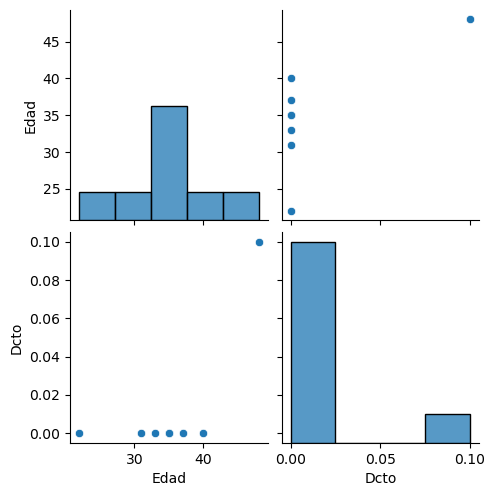

In [146]:
# Gráfico tipo pairplot
sns.pairplot(df_clase)

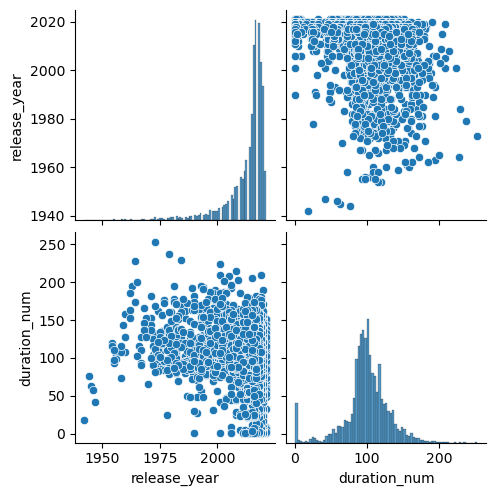

In [150]:
# Eliminar filas con duplicados y nulos
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df.drop('Unnamed: 0', axis = 1, inplace=True)
# Visualizar 
sns.pairplot(df)

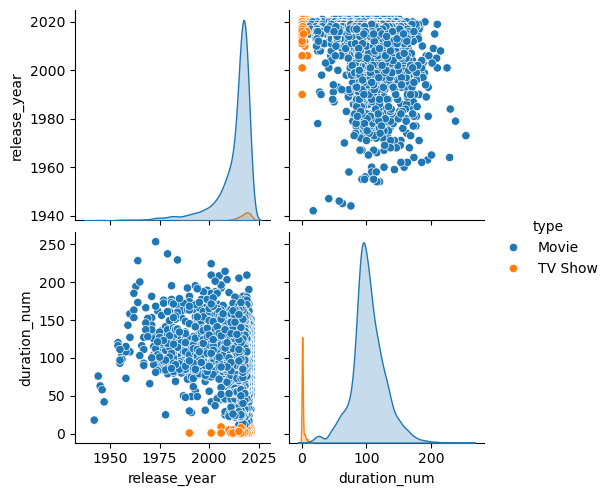

In [155]:
# Visualizar el pairplot de los tipos del df
sns.pairplot(df, hue = 'type')